In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [67]:
df = pd.read_csv(r"D:\Notes of CampusX\DL with CampusX\Dataset\ushape.csv")

In [68]:
df.head()

,X,Y,CLASS
0,2.1200,-0.0462,1.0
1,0.8820,-0.0758,0.0
2,-0.0551,-0.0373,1.0
3,0.8300,-0.5390,1.0
4,2.1100,0.6620,1.0


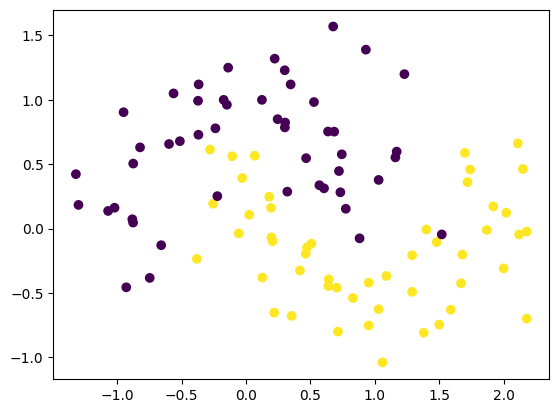

In [69]:
plt.scatter(df['X'],df['Y'],c=df['CLASS'])

In [70]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [71]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [72]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_10 (Dense)            (None, 10)                30        
                                                                 
 dense_11 (Dense)            (None, 1)                 11        
                                                                 
Total params: 41
Trainable params: 41
Non-trainable params: 0
_________________________________________________________________


In [73]:
# Set parameters to 0
model.get_weights()

[array([[ 0.4774806 ,  0.32113248, -0.4749299 ,  0.4470498 ,  0.5142576 ,
         -0.5117199 ,  0.11193377, -0.09347296,  0.40740305,  0.54187447],
        [ 0.03375912,  0.22181463, -0.2937062 , -0.3273551 , -0.6838995 ,
          0.29948062,  0.10475683, -0.33406383,  0.01724225, -0.51505625]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.3470096 ],
        [-0.33401898],
        [-0.18125623],
        [ 0.6806038 ],
        [ 0.4278857 ],
        [-0.3500183 ],
        [-0.0082916 ],
        [ 0.7143083 ],
        [ 0.68079597],
        [-0.31921825]], dtype=float32),
 array([0.], dtype=float32)]

In [74]:
initial_weights = model.get_weights()

In [75]:
initial_weights[0] = np.zeros(model.get_weights()[0].shape)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.zeros(model.get_weights()[2].shape)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)

In [76]:
model.set_weights(initial_weights)

In [77]:
model.get_weights()

[array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [78]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [79]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 [==============================] - 0s 54ms/step - loss: 0.6935 - accuracy: 0.4051 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 2/100
3/3 [==============================] - 0s 15ms/step - loss: 0.6932 - accuracy: 0.5063 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 3/100
3/3 [==============================] - 0s 13ms/step - loss: 0.6932 - accuracy: 0.5063 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 4/100
3/3 [==============================] - 0s 14ms/step - loss: 0.6932 - accuracy: 0.5063 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 5/100
3/3 [==============================] - 0s 13ms/step - loss: 0.6933 - accuracy: 0.5063 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 6/100
3/3 [==============================] - 0s 14ms/step - loss: 0.6931 - accuracy: 0.5063 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 7/100
3/3 [==============================] - 0s 13ms/step - loss: 0.6931 - accuracy: 0.5063 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 8/100
3/3 [===

In [80]:
model.get_weights()

[array([[ 0.4359617,  0.4359617,  0.4359617,  0.4359617,  0.4359617,
          0.4359617,  0.4359617,  0.4359617,  0.4359617,  0.4359617],
        [-0.4781514, -0.4781514, -0.4781514, -0.4781514, -0.4781514,
         -0.4781514, -0.4781514, -0.4781514, -0.4781514, -0.4781514]],
       dtype=float32),
 array([-0.12389792, -0.12389792, -0.1238979 , -0.1238979 , -0.12389793,
        -0.12389793, -0.12389791, -0.12389791, -0.12389792, -0.12389792],
       dtype=float32),
 array([[0.05835156],
        [0.05835156],
        [0.05835157],
        [0.05835157],
        [0.05835156],
        [0.05835156],
        [0.05835157],
        [0.05835157],
        [0.05835156],
        [0.05835156]], dtype=float32),
 array([-0.05638938], dtype=float32)]

9600/9600 [==============================] - 7s 777us/step


<Axes: >

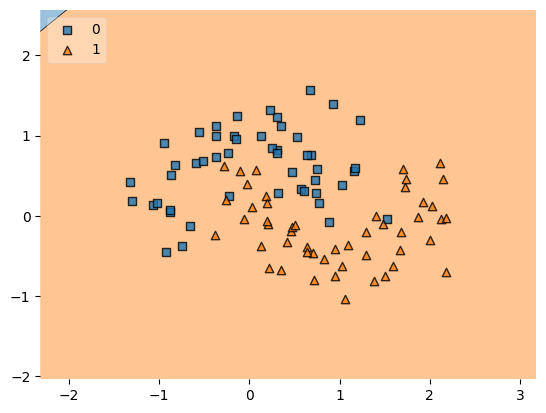

In [81]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)